In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Preprocesamiento
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Selección de características
from sklearn.feature_selection import SequentialFeatureSelector

# Reducción de dimensionalidad
from sklearn.decomposition import PCA

# Model selection
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV

# Métricas
from sklearn.metrics import accuracy_score, classification_report, recall_score, roc_auc_score, roc_curve, auc, confusion_matrix, f1_score

# Pipelines y balanceo
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

In [ ]:
churn_train = pd.read_csv('churn_train_clean.csv')
churn_test = pd.read_csv('churn_test_clean.csv')

In [ ]:
X_train = churn_train.drop(columns='Churn Value')
Y_train = churn_train['Churn Value']
X_test = churn_test.drop(columns='Churn Value')
Y_test = churn_test['Churn Value']

#   Introduccion de variables y procesamiento

Primero vamos a definir un baseline model con el cual compararnos

In [ ]:
#Primero hay que labelear las columnas categóricas para que el modelo las pueda usar
columnas_a_codificar = [
    "Gender", "Senior Citizen", "Partner", "Dependents",
    "Phone Service", "Multiple Lines", "Internet Service",
    "Online Security", "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV", "Streaming Movies",
    "Contract", "Paperless Billing", "Payment Method"
]

for col in columnas_a_codificar:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col])  
    X_test[col] = le.transform(X_test[col])        

In [ ]:
rl = LogisticRegression( random_state=10)
rl.fit(X_train,Y_train)   
prediccion = rl.predict(X_test)
print(classification_report(Y_test,prediccion))

              precision    recall  f1-score   support

           0       0.85      0.88      0.86      1294
           1       0.63      0.56      0.59       467

    accuracy                           0.80      1761
   macro avg       0.74      0.72      0.73      1761
weighted avg       0.79      0.80      0.79      1761



c:\Users\david\Desktop\MASTER\entorno\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Como podemos comprobar con el warning el modelo ha llegado al límite por defecto de iteraciones y no ha convergido, eso se soluciona o bien normalizando las variables numéricas o bien aumentando el número de iteraciones.

In [ ]:
columnas_a_escalar = ["Total Charges", 'Monthly Charges', 'Tenure Months','CLTV']

scaler = StandardScaler()
X_train[columnas_a_escalar] = scaler.fit_transform(X_train[columnas_a_escalar])
X_test[columnas_a_escalar] = scaler.transform(X_test[columnas_a_escalar])

In [ ]:
rl = LogisticRegression( random_state=10)
rl.fit(X_train,Y_train)   
prediccion = rl.predict(X_test)
print(classification_report(Y_test,prediccion))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1294
           1       0.64      0.55      0.59       467

    accuracy                           0.80      1761
   macro avg       0.74      0.72      0.73      1761
weighted avg       0.79      0.80      0.79      1761



Tras normalizar se puede observar que el modelo no da warning y ha podido converger en las 100 iteraciones de límite por defecto.

Para buscar una forma automática de seleccionar las variables del modelo vamos a usar dos funciones:

El Sequential Feature Selector (SFS) es un método de selección de variables basado en modelos que trabaja de forma iterativa evaluando el rendimiento del modelo, en nuestro caso una regresión logistica, utilizando la métrica definida, que fue F1-macro. Dependiendo del parámetro direction, el SFS puede funcionar en modo forward, empezando sin variables y añadiéndolas una a una, o en modo backward, comenzando con todas las variables y eliminándolas una a una. El proceso continúa hasta que añadir o quitar cualquier variable deja de mejorar el promedio de la métrica en validación cruzada. De esta manera, el SFS selecciona el subconjunto de variables que maximiza el rendimiento del modelo.


Por su parte, SelectKBest es un método univariado que selecciona las variables basándose en su relación individual con la variable objetivo. En nuestro caso, se utilizó el ANOVA F-test, que mide si las medias de la variable objetivo difieren significativamente entre los distintos valores de cada característica. SelectKBest selecciona las k variables con mayor puntuación F, es decir, aquellas que presentan la relación estadística más fuerte con la variable objetivo.

In [ ]:
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, f1_score

# =============================
# 1. BÚSQUEDA DEL MEJOR NÚMERO DE FEATURES (CV solo TRAIN)
# =============================
n_features_range = range(5, 20)  # 5,7,9,...

best_n_features = None
best_f1 = 0
best_features = None


for n_features in n_features_range:
    print(f"Probando n_features = {n_features}")
    model = LogisticRegression(random_state=10, max_iter=1000)

    sfs = SequentialFeatureSelector(
        estimator=model,
        n_features_to_select=n_features,
        direction='backward',          # o 'forward' si quieres más rápido
        scoring='f1_macro',
        cv=5,
        n_jobs=-1
    )

    sfs.fit(X_train, Y_train)
    selected_cols = X_train.columns[sfs.get_support()]

    X_train_sfs = X_train[selected_cols]

    f1_cv = cross_val_score(
        model,
        X_train_sfs,
        Y_train,
        cv=5,
        scoring='f1_macro'
    ).mean()

    print(f" → F1-macro CV: {f1_cv:.4f}")

    if f1_cv > best_f1:
        best_f1 = f1_cv
        best_n_features = n_features
        best_features = selected_cols

print("\n==============================")
print(f"Mejor nº de features: {best_n_features}")
print(f"Mejor F1-macro CV: {best_f1:.4f}")
print(f"Features seleccionadas ({len(best_features)}):")
print(best_features.tolist())

# =============================
# 2. ENTRENAR MODELO FINAL CON EL MEJOR SUBCONJUNTO
# =============================
final_model = LogisticRegression(random_state=10, max_iter=1000)
X_train_final = X_train[best_features]
X_test_final  = X_test[best_features]

final_model.fit(X_train_final, Y_train)

# =============================
# 3. EVALUACIÓN FINAL EN TEST
# =============================
y_test_pred = final_model.predict(X_test_final)

print("\n=== Classification Report (TEST) ===")
print(classification_report(Y_test, y_test_pred))

f1_test = f1_score(Y_test, y_test_pred, average="macro")
print(f"F1-macro en TEST: {f1_test:.4f}")


Buscando mejor número de features con SFS + CV (solo TRAIN)

Probando n_features = 5
 → F1-macro CV: 0.7319
Probando n_features = 6
 → F1-macro CV: 0.7362
Probando n_features = 7
 → F1-macro CV: 0.7406
Probando n_features = 8
 → F1-macro CV: 0.7417
Probando n_features = 9
 → F1-macro CV: 0.7467
Probando n_features = 10
 → F1-macro CV: 0.7470
Probando n_features = 11
 → F1-macro CV: 0.7474
Probando n_features = 12
 → F1-macro CV: 0.7499
Probando n_features = 13
 → F1-macro CV: 0.7513
Probando n_features = 14
 → F1-macro CV: 0.7518
Probando n_features = 15
 → F1-macro CV: 0.7515
Probando n_features = 16
 → F1-macro CV: 0.7513
Probando n_features = 17
 → F1-macro CV: 0.7507
Probando n_features = 18
 → F1-macro CV: 0.7502
Probando n_features = 19
 → F1-macro CV: 0.7505

Mejor nº de features: 14
Mejor F1-macro CV: 0.7518
Features seleccionadas (14):
['Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech 

In [ ]:
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, f1_score

# =============================
# 1. BÚSQUEDA DEL MEJOR NÚMERO DE FEATURES (CV solo TRAIN)
# =============================
n_features_range = range(5, 20)  # 5,7,9,...

best_n_features = None
best_f1 = 0
best_features = None

print("Buscando mejor número de features con SFS + CV (solo TRAIN)\n")

for n_features in n_features_range:
    print(f"Probando n_features = {n_features}")

    model = LogisticRegression(random_state=10, max_iter=1000)

    sfs = SequentialFeatureSelector(
        estimator=model,
        n_features_to_select=n_features,
        direction='forward',          # o 'forward' si quieres más rápido
        scoring='f1_macro',
        cv=5,
        n_jobs=-1
    )

    sfs.fit(X_train, Y_train)
    selected_cols = X_train.columns[sfs.get_support()]

    X_train_sfs = X_train[selected_cols]

    f1_cv = cross_val_score(
        model,
        X_train_sfs,
        Y_train,
        cv=5,
        scoring='f1_macro'
    ).mean()

    print(f" → F1-macro CV: {f1_cv:.4f}")

    if f1_cv > best_f1:
        best_f1 = f1_cv
        best_n_features = n_features
        best_features = selected_cols

print("\n==============================")
print(f"Mejor nº de features: {best_n_features}")
print(f"Mejor F1-macro CV: {best_f1:.4f}")
print(f"Features seleccionadas ({len(best_features)}):")
print(best_features.tolist())

# =============================
# 2. ENTRENAR MODELO FINAL CON EL MEJOR SUBCONJUNTO
# =============================
final_model = LogisticRegression(random_state=10, max_iter=1000)
X_train_final = X_train[best_features]
X_test_final  = X_test[best_features]

final_model.fit(X_train_final, Y_train)

# =============================
# 3. EVALUACIÓN FINAL EN TEST
# =============================
y_test_pred = final_model.predict(X_test_final)

print("\n=== Classification Report (TEST) ===")
print(classification_report(Y_test, y_test_pred))

f1_test = f1_score(Y_test, y_test_pred, average="macro")
print(f"F1-macro en TEST: {f1_test:.4f}")


Buscando mejor número de features con SFS + CV (solo TRAIN)

Probando n_features = 5
 → F1-macro CV: 0.7319
Probando n_features = 6
 → F1-macro CV: 0.7379
Probando n_features = 7
 → F1-macro CV: 0.7404
Probando n_features = 8
 → F1-macro CV: 0.7423
Probando n_features = 9
 → F1-macro CV: 0.7420
Probando n_features = 10
 → F1-macro CV: 0.7466
Probando n_features = 11
 → F1-macro CV: 0.7469
Probando n_features = 12
 → F1-macro CV: 0.7477
Probando n_features = 13
 → F1-macro CV: 0.7489
Probando n_features = 14
 → F1-macro CV: 0.7483
Probando n_features = 15
 → F1-macro CV: 0.7485
Probando n_features = 16
 → F1-macro CV: 0.7483
Probando n_features = 17
 → F1-macro CV: 0.7496
Probando n_features = 18
 → F1-macro CV: 0.7474
Probando n_features = 19
 → F1-macro CV: 0.7481

Mejor nº de features: 17
Mejor F1-macro CV: 0.7496
Features seleccionadas (17):
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security'

In [ ]:
# =============================
# 1. BÚSQUEDA DE MEJOR k (CV)
# =============================

k_range = range(1, 21)

best_k = None
best_f1_cv = 0

print("Buscando mejor k con validación cruzada (solo TRAIN)\n")

for k in k_range:
    selector = SelectKBest(score_func=f_classif, k=k)
    X_train_k = selector.fit_transform(X_train, Y_train)

    model = LogisticRegression(random_state=10, max_iter=1000)

    f1_cv = cross_val_score(
        model,
        X_train_k,
        Y_train,
        cv=5,
        scoring="f1_macro"
    ).mean()

    print(f"k={k} → F1-macro CV: {f1_cv:.4f}")

    if f1_cv > best_f1_cv:
        best_f1_cv = f1_cv
        best_k = k

print("\n==============================")
print(f"Mejor k seleccionado por CV: {best_k}")
print(f"Mejor F1-macro CV: {best_f1_cv:.4f}")

# =============================
# 2. ENTRENAR MODELO FINAL
# =============================

best_selector = SelectKBest(score_func=f_classif, k=best_k)
X_train_best = best_selector.fit_transform(X_train, Y_train)
X_test_best = best_selector.transform(X_test)

final_model = LogisticRegression(random_state=10, max_iter=1000)
final_model.fit(X_train_best, Y_train)

# =============================
# 3. EVALUACIÓN FINAL EN TEST
# =============================

y_test_pred = final_model.predict(X_test_best)

print("\n=== Classification Report (TEST) ===")
print(classification_report(Y_test, y_test_pred))

f1_test = f1_score(Y_test, y_test_pred, average="macro")
print(f"F1-macro en TEST: {f1_test:.4f}")

# =============================
# 4. FEATURES SELECCIONADAS
# =============================

selected_columns = X_train.columns[best_selector.get_support()]
print(f"\nColumnas seleccionadas ({len(selected_columns)}):")
print(selected_columns.tolist())


Buscando mejor k con validación cruzada (solo TRAIN)

k=1 → F1-macro CV: 0.4235
k=2 → F1-macro CV: 0.5633
k=3 → F1-macro CV: 0.6934
k=4 → F1-macro CV: 0.7244
k=5 → F1-macro CV: 0.7116
k=6 → F1-macro CV: 0.7308
k=7 → F1-macro CV: 0.7293
k=8 → F1-macro CV: 0.7328
k=9 → F1-macro CV: 0.7364
k=10 → F1-macro CV: 0.7342
k=11 → F1-macro CV: 0.7336
k=12 → F1-macro CV: 0.7334
k=13 → F1-macro CV: 0.7357
k=14 → F1-macro CV: 0.7359
k=15 → F1-macro CV: 0.7368
k=16 → F1-macro CV: 0.7382
k=17 → F1-macro CV: 0.7406
k=18 → F1-macro CV: 0.7394
k=19 → F1-macro CV: 0.7401
k=20 → F1-macro CV: 0.7482

Mejor k seleccionado por CV: 20
Mejor F1-macro CV: 0.7482

=== Classification Report (TEST) ===
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1294
           1       0.64      0.55      0.59       467

    accuracy                           0.80      1761
   macro avg       0.74      0.72      0.73      1761
weighted avg       0.79      0.80      0.79   

## CONCLUSIÓN
-Ambos métodos (SFS y Kbest) muestran rendimientos muy similares y las diferencias en F1-macro entre un subconjunto optimizado y el conjunto completo son mínimas.

-Esto indica que ninguna selección de variables aporta una mejora significativa sobre el modelo con todas las características originales.

-Por simplicidad y claridad en la interpretación del modelo, se decide mantener todas las variables originales en el modelo final.

# PCA ¿Se puede reducir la dimensión del dataset? ¿Merece la pena?

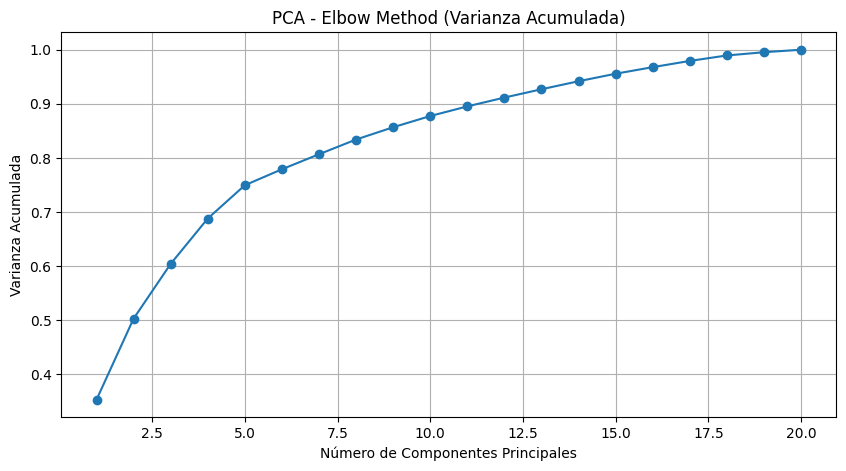

In [ ]:

# Ajustar PCA completo (tantos componentes como variables tengas)
pca_full = PCA().fit(X_train)

# Varianza individual y acumulada
var_exp = pca_full.explained_variance_ratio_
var_exp_cum = np.cumsum(var_exp)
plt.figure(figsize=(10,5))
plt.plot(range(1, len(var_exp_cum) + 1), var_exp_cum, marker='o')
plt.title("PCA - Elbow Method (Varianza Acumulada)")
plt.xlabel("Número de Componentes Principales")
plt.ylabel("Varianza Acumulada")
plt.grid(True)
plt.show()

In [ ]:
pca = PCA(n_components=13) 
pca.fit(X_train)

X_train_pca = pca.transform(X_train)
X_test_pca  = pca.transform(X_test)

print("Varianza total capturada por las 13 componentes:", np.sum(pca.explained_variance_ratio_))

# --- 2. Regresión Logística ---
logistica = LogisticRegression(class_weight='balanced', random_state=42, max_iter=500)
logistica.fit(X_train_pca, Y_train)

# --- 3. Predicciones ---
y_test_pred  = logistica.predict(X_test_pca)
y_test_proba = logistica.predict_proba(X_test_pca)[:, 1]

# --- 5. Reporte detallado ---
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(Y_test, y_test_pred))

Varianza total capturada por las 13 componentes: 0.9269209374718541

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1294
           1       0.51      0.79      0.62       467

    accuracy                           0.74      1761
   macro avg       0.71      0.76      0.71      1761
weighted avg       0.80      0.74      0.75      1761



Se observó con el elbow method que para capturar por lo menos el 90% de la varianza se necesitarían al menos 13 componentes de un total de 20 variables. La reducción de dimensionalidad es moderada y, al transformar las variables originales en combinaciones lineales, se pierde interpretabilidad y existe el riesgo de una ligera disminución en la precisión del modelo. Dado que el modelo de regresión logítica puede manejar cómodamente las 20 variables originales, no hay una ganancia significativa en aplicar PCA.